Model Evaluation

In [1]:
# 1. Import required libraries

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# 2. Identify the project root directory

current_dir = Path.cwd()

if current_dir.name == "notebooks":
    PROJECT_ROOT = current_dir.parent
else:
    PROJECT_ROOT = current_dir

# 3. Define the results directories

METRICS_DIR = PROJECT_ROOT / "results" / "metrics"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"

# Create figures directory if it doesn't exist
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# 4. Check the project paths

print("Project root:", PROJECT_ROOT)
print("Metrics directory exists:", METRICS_DIR.exists())
print("Figures directory exists:", FIGURES_DIR.exists())

Project root: d:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L
Metrics directory exists: True
Figures directory exists: True


Load the five-fold predictions

In [2]:
# Load and combine predictions from all five folds

all_fold_predictions = []

for fold in range(1, 6):

    file_path = METRICS_DIR / f"fold{fold}_test_predictions.csv"

    fold_df = pd.read_csv(file_path)

    # Use Texture as actual_class if actual_class is missing
    if "actual_class" not in fold_df.columns:
        fold_df["actual_class"] = fold_df["Texture"]

    # Keep only the required evaluation columns
    fold_df = fold_df[
        [
            "image_filename",
            "actual_class",
            "predicted_class",
            "confidence"
        ]
    ].copy()

    # Record which fold produced the prediction
    fold_df["fold"] = fold

    all_fold_predictions.append(fold_df)


# Combine all five folds
combined_predictions = pd.concat(
    all_fold_predictions,
    ignore_index=True
)

# Standardise class names
combined_predictions["actual_class"] = (
    combined_predictions["actual_class"].astype(str).str.strip().str.lower()
)

combined_predictions["predicted_class"] = (
    combined_predictions["predicted_class"].astype(str).str.strip().str.lower()
)

# Calculate whether each prediction is correct
combined_predictions["correct"] = (
    combined_predictions["actual_class"]
    == combined_predictions["predicted_class"]
)

# Display results
print("Combined prediction shape:", combined_predictions.shape)

print("\nMissing values:")
print(combined_predictions.isnull().sum())

print("\nTotal correct predictions:", combined_predictions["correct"].sum())
print("Total predictions:", len(combined_predictions))

Combined prediction shape: (130, 6)

Missing values:
image_filename     0
actual_class       0
predicted_class    0
confidence         0
fold               0
correct            0
dtype: int64

Total correct predictions: 102
Total predictions: 130


Calculate overall model performance

In [3]:
# Define the three fabric classes
class_names = ["plain", "satin", "twill"]

# Calculate overall accuracy
overall_accuracy = accuracy_score(
    combined_predictions["actual_class"],
    combined_predictions["predicted_class"]
)

# Generate classification report
report = classification_report(
    combined_predictions["actual_class"],
    combined_predictions["predicted_class"],
    labels=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

# Generate confusion matrix
cm = confusion_matrix(
    combined_predictions["actual_class"],
    combined_predictions["predicted_class"],
    labels=class_names
)

# Display results
print(f"Overall Accuracy: {overall_accuracy:.4f}")

print("\nClassification Report:")
display(report_df.round(4))

print("\nConfusion Matrix:")
display(
    pd.DataFrame(
        cm,
        index=[f"Actual {name}" for name in class_names],
        columns=[f"Predicted {name}" for name in class_names]
    )
)

Overall Accuracy: 0.7846

Classification Report:


,precision,recall,f1-score,support
plain,0.7600,0.7600,0.7600,50.0000
satin,0.7021,0.8049,0.7500,41.0000
twill,0.9394,0.7949,0.8611,39.0000
accuracy,0.7846,0.7846,0.7846,0.7846
macro avg,0.8005,0.7866,0.7904,130.0000
weighted avg,0.7956,0.7846,0.7872,130.0000



Confusion Matrix:


,Predicted plain,Predicted satin,Predicted twill
Actual plain,38,12,0
Actual satin,6,33,2
Actual twill,6,2,31


Calculate performance for each fold

In [4]:
# Calculate accuracy separately for each fold

fold_results = []

for fold in range(1, 6):

    fold_df = combined_predictions[
        combined_predictions["fold"] == fold
    ]

    fold_accuracy = accuracy_score(
        fold_df["actual_class"],
        fold_df["predicted_class"]
    )

    fold_results.append({
        "fold": fold,
        "test_images": len(fold_df),
        "correct_predictions": fold_df["correct"].sum(),
        "incorrect_predictions": (~fold_df["correct"]).sum(),
        "accuracy": fold_accuracy
    })

fold_results_df = pd.DataFrame(fold_results)

print("Individual Fold Performance:")
display(fold_results_df.round(4))

print(
    "\nMean Fold Accuracy:",
    round(fold_results_df["accuracy"].mean(), 4)
)

print(
    "Standard Deviation:",
    round(fold_results_df["accuracy"].std(), 4)
)

Individual Fold Performance:


,fold,test_images,correct_predictions,incorrect_predictions,accuracy
0,1,27,16,11,0.5926
1,2,23,20,3,0.8696
2,3,30,23,7,0.7667
3,4,26,25,1,0.9615
4,5,24,18,6,0.7500



Mean Fold Accuracy: 0.7881
Standard Deviation: 0.1386


Visualise fold performance

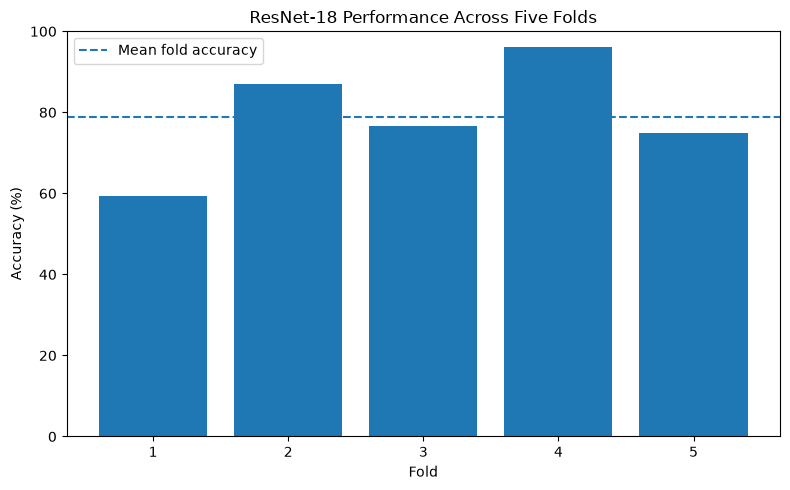

In [5]:
# Plot accuracy for each fold

plt.figure(figsize=(8, 5))

plt.bar(
    fold_results_df["fold"].astype(str),
    fold_results_df["accuracy"] * 100
)

plt.axhline(
    y=fold_results_df["accuracy"].mean() * 100,
    linestyle="--",
    label="Mean fold accuracy"
)

plt.xlabel("Fold")
plt.ylabel("Accuracy (%)")
plt.title("ResNet-18 Performance Across Five Folds")
plt.ylim(0, 100)
plt.legend()

plt.tight_layout()

# Save figure
plt.savefig(
    FIGURES_DIR / "five_fold_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Save the evaluation results

In [6]:
# Save overall classification report
report_df.to_csv(
    METRICS_DIR / "overall_classification_report.csv"
)

# Save overall confusion matrix
confusion_matrix_df = pd.DataFrame(
    cm,
    index=[f"Actual_{name}" for name in class_names],
    columns=[f"Predicted_{name}" for name in class_names]
)

confusion_matrix_df.to_csv(
    METRICS_DIR / "overall_confusion_matrix.csv"
)

# Save combined predictions
combined_predictions.to_csv(
    METRICS_DIR / "combined_test_predictions.csv",
    index=False
)

# Save fold performance
fold_results_df.to_csv(
    METRICS_DIR / "fold_accuracy_summary.csv",
    index=False
)

print("All baseline evaluation results saved successfully!")

All baseline evaluation results saved successfully!


Check your saved files

In [7]:
print("Saved evaluation files:")

for file_path in [
    METRICS_DIR / "overall_classification_report.csv",
    METRICS_DIR / "overall_confusion_matrix.csv",
    METRICS_DIR / "combined_test_predictions.csv",
    METRICS_DIR / "fold_accuracy_summary.csv",
    FIGURES_DIR / "five_fold_accuracy.png"
]:
    print(file_path.name, "->", file_path.exists())

Saved evaluation files:
overall_classification_report.csv -> True
overall_confusion_matrix.csv -> True
combined_test_predictions.csv -> True
fold_accuracy_summary.csv -> True
five_fold_accuracy.png -> True
